In [1]:
import pandas as pd
import seaborn as sns

# Linear Regression — Medical Insurance Charges

## Goal
Predict medical insurance charges using demographic and health-related features.

Linear regression models the target as:$$
y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \epsilon
$$

where:
- β₀ = intercept
- βᵢ = learned coefficients
- xᵢ = input features
- ε = unexplained error

The model learns coefficients that minimize the sum of squared residuals.

In [2]:
insurance_data = pd.read_csv("insurance.csv")

In [3]:
insurance_data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
insurance_data.shape

(1338, 7)

In [5]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
insurance_data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Target: charges

Features:
age,
sex,
bmi,
children,
smoker,
region

In [7]:
insurance_data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

<Axes: xlabel='bmi', ylabel='charges'>

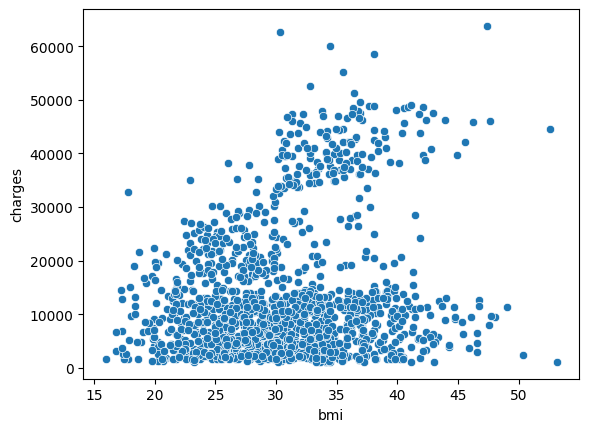

In [8]:
# Visualize
sns.scatterplot(x=insurance_data["bmi"], y=insurance_data["charges"])

- 1338 rows, 7 columns
- no missing values
- target is charges
- categorical features are sex, smoker, region
- numerical features are age, bmi, children
- For the initial baseline, I exclude `region` to keep the preprocessing simple.
- A later experiment will include it using one-hot encoding and compare performance.

<Axes: xlabel='bmi', ylabel='charges'>

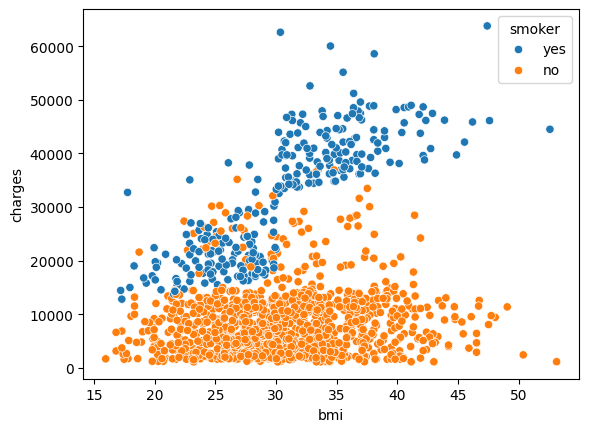

In [9]:
sns.scatterplot(x=insurance_data["bmi"], y=insurance_data["charges"], hue=insurance_data["smoker"])

- charges tend to be much higher for smokers
- BMI appears to matter differently for smokers vs non-smokers
- this motivates later interaction features like bmi × smoker

In [10]:
X = insurance_data.drop(columns=["charges", "region"])
y = insurance_data["charges"]

# binary categorical variables, so simple 0/1 encoding is appropriate.
X["sex"] = X["sex"].map({"female":1, "male":0})
X["smoker"] = X["smoker"].map({"yes":1, "no":0})

In [11]:
X.head()

,age,sex,bmi,children,smoker
0,19,1,27.900,0,1
1,18,0,33.770,1,0
2,28,0,33.000,3,0
3,33,0,22.705,0,0
4,32,0,28.880,0,0


In [12]:
# Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Experiment 1 — Baseline Model

In [13]:
X_test.head()

,age,sex,bmi,children,smoker
764,45,1,25.175,2,0
887,36,1,30.020,0,0
890,64,1,26.885,0,1
1293,46,0,25.745,3,0
259,19,0,31.920,0,1


In [14]:
# Train Model

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [15]:
# Predict Values
y_pred = model.predict(X_test)

In [16]:
# Evaluate
from sklearn.metrics import r2_score

baseline_r2 = r2_score(y_test, y_pred)
n = X_test.shape[0]
p = X_test.shape[1]
baseline_adjusted_r2 = 1 - ((1 - baseline_r2) * (n - 1) / (n - p - 1))

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_mae = mean_absolute_error(y_test, y_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE: ", baseline_mae)  #On average, how many dollars am I off?
print("RMSE: ", baseline_rmse)  #It penalizes large errors more heavily.
print("R^2: :", baseline_r2)  #How much of the variance in the target is explained by the model?
print("adjusted r^2", baseline_adjusted_r2)

MAE:  4213.484797807139
RMSE:  5829.17293025419
R^2: : 0.7811302113434095
adjusted r^2 0.7769533069797342


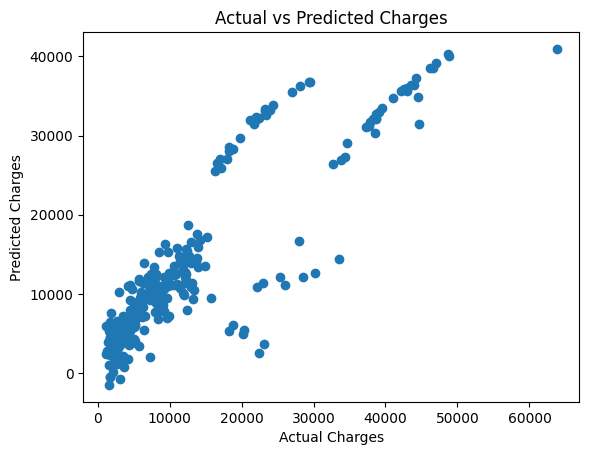

In [18]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")
plt.show()

- perfect predictions would lie near the diagonal
- deviations from that line represent prediction error
- large deviations suggest cases the linear model struggles with

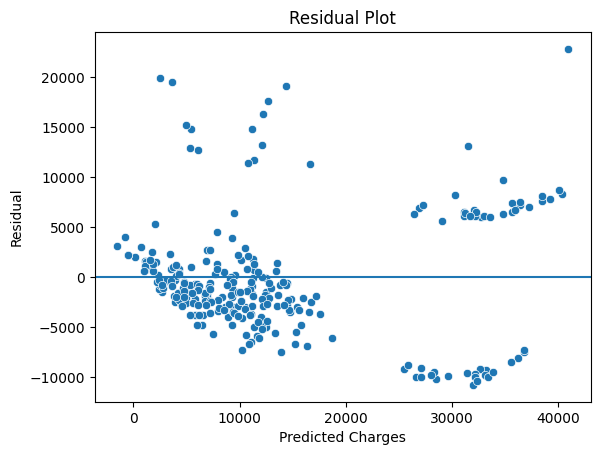

In [19]:
residuals = y_test - y_pred

sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0)
plt.xlabel("Predicted Charges")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

- residuals should ideally be randomly scattered around zero
- visible structure suggests missing relationships
- changing spread may indicate heteroscedasticity
- this model likely misses some nonlinear/interaction effects

In [20]:
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.coef_
})

In [21]:
coef_df

,feature,coefficient
0,age,257.068962
1,sex,7.951788
2,bmi,327.533514
3,children,427.254431
4,smoker,23653.903315


- age coefficient: expected change in predicted charges for +1 year, holding other features fixed
- BMI coefficient: expected change for +1 BMI unit
- smoker coefficient: estimated difference between smoker and non-smoker, holding other features fixed
- association does not imply causation

In [22]:
#The intercept is mathematically necessary for the fitted equation, but it may not have a meaningful real-world interpretation here.
print("Intercept: ", model.intercept_)

Intercept:  -12121.403039282884


In [23]:
baseline_pred = [y_train.mean()] * len(y_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)

In [24]:
print("Baseline MAE:", baseline_mae)
print("Linear Regression MAE:", baseline_mae)

Baseline MAE: 9593.33846086229
Linear Regression MAE: 9593.33846086229


## Interview Questions

### Why does linear regression use squared error?
Squared error is differentiable, penalizes large errors strongly,
and under Gaussian noise corresponds to maximum likelihood estimation.

### MAE vs MSE?
MAE is more robust to large errors.
MSE penalizes large errors more heavily.

### What does R² mean?
The fraction of target variance explained relative to predicting
the mean target value.

### Does a high R² imply causation?
No.

### When would linear regression perform poorly?
When relationships are strongly nonlinear, interactions are important,
outliers dominate, or assumptions are substantially violated.

## Experiment 2 — Add Region

In [25]:
X = insurance_data.drop(columns=['charges'])
y = insurance_data['charges']

X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

X["sex"] = X["sex"].map({"female":1, "male":0})
X["smoker"] = X["smoker"].map({"yes":1, "no":0})

- region is nominal, so assigning arbitrary numbers such as 0,1,2,3 would create a fake ordering. 
- One-hot encoding avoids that assumption.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

region_r2 = r2_score(y_test, y_pred)
print("r2 score: ", region_r2)

r2 score:  0.7835929767120724


## Experiment 3 — Add Interaction Features

In [27]:
# Interaction Features
X = insurance_data.drop(columns=["charges"])
y = insurance_data["charges"]

X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

X["sex"] = X["sex"].map({"female": 1, "male": 0})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

X["age_smoker"] = X["age"] * X["smoker"]
X["bmi_smoker"] = X["bmi"] * X["smoker"]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

interaction_r2 = r2_score(y_test, y_pred)
print("r2 score: ", interaction_r2)

r2 score:  0.865231697953168


In [29]:
# Low train R² and low test R² -> possible underfitting / high bias
# High train R² but much lower test R² -> possible overfitting / high variance
# Similar and reasonably strong train/test R² -> better generalization

y_train_pred = model.predict(X_train)
r2_train = r2_score(y_train, y_train_pred)
print("training data r2: ", r2_train)
print("testing data r2: ", interaction_r2)

training data r2:  0.8340713711218875
testing data r2:  0.865231697953168


The train and test scores are fairly close, so there is no obvious severe overfitting signal. The slightly higher test score can occur due to random split variation.

In [30]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "With Region",
        "With Interactions"
    ],
    "R2": [
        baseline_r2,
        region_r2,
        interaction_r2
    ]
})
print(comparison)

               Model        R2
0           Baseline  0.781130
1        With Region  0.783593
2  With Interactions  0.865232


****Assumptions****
- linearity
- independent errors
- constant variance
- no perfect multicollinearity
- residual normality mainly for inference

****Limitations****
- Single train-test split: The model was evaluated using only one train-test split, so the reported performance may depend on that particular split. Cross-validation would give a more reliable estimate of generalization performance.
- No cross-validation: Hyperparameters and model choices were not validated across multiple folds. This means the current results should be treated as an initial baseline rather than a final performance estimate.
- Linear relationship assumption: Linear Regression assumes the target can be modeled reasonably well as a linear combination of the input features. Real-world relationships, especially between medical charges and variables such as BMI or age, may be nonlinear.
- Limited feature engineering: Only a small number of engineered features/interactions were explored. Other useful transformations, interaction terms, or nonlinear features may improve the model.
- Target distribution and outliers: Medical charges can contain large values and may be highly skewed. Because Linear Regression and squared-error-based fitting are sensitive to large residuals, extreme observations may strongly influence the fitted model.
- Regression assumptions were not formally tested: Residual normality, homoscedasticity, independence, and multicollinearity were discussed or visually inspected, but no detailed statistical diagnostic tests were performed.

****Conclusion****
- baseline linear regression already captures substantial signal
- region adds little
- smoker-related interaction features improve performance significantly
- linear regression remains interpretable
- model may still miss nonlinear effects
- *future work*: cross-validation, regularization, pipelines, nonlinear models